# 1. Configuração

In [48]:
from pathlib import Path

import numpy as np
import cv2 # Processamento de imagens
import matplotlib.pyplot as plt
import pandas as pd

# Métrica para comparação dos rostos
from sklearn.metrics.pairwise import cosine_similarity
# Modelo pré-treinado para gerar embeddings faciais
from deepface import DeepFace

In [49]:
# Configurações do projeto
MODEL_NAME = "Facenet512"

print("Ambiente configurado com sucesso!")
print(f"Modelo facial selecionado: {MODEL_NAME}")

Ambiente configurado com sucesso!
Modelo facial selecionado: Facenet512


# 2. Carregar dataset

In [50]:
DATASET_DIR = Path("dataset")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"O diretório '{DATASET_DIR}' não foi encontrado."
    )

print(f"Dataset encontrado em: {DATASET_DIR.resolve()}")

Dataset encontrado em: C:\Users\gabis\fiap-fase6-implementing-facial-recognition\dataset


In [51]:
# Descobrindo as pessoas automáticamente
pessoas = sorted([
    pasta.name
    for pasta in DATASET_DIR.iterdir()
    if pasta.is_dir()
])

print(f"Quantidade de pessoas encontradas: {len(pessoas)}")

for pessoa in pessoas:
    print(f"- {pessoa}")

Quantidade de pessoas encontradas: 3
- Gabriela
- Tom Holland
- Zendaya


In [ ]:
# Separando teste e treino
dataset = {}

for pessoa in pessoas:
    pasta = DATASET_DIR / pessoa

    imagens_treino = []

    imagens_treino = sorted((pasta / "treino").glob("*"))

    # Imagem 5 = teste
    imagem_teste = sorted((pasta / "teste").glob("*")) if (pasta / "teste").exists() else None

    dataset[pessoa] = {
        "treino": imagens_treino,
        "teste": imagem_teste
    }

Validação

In [53]:
dataset_valido = True

for pessoa, dados in dataset.items():

    if len(dados["treino"]) < 4:
        print(
            f"Pessoa '{pessoa}' não possui "
            "4 imagens de treinamento."
        )
        dataset_valido = False

    if dados["teste"] is None:
        print(
            f"Pessoa '{pessoa}' não possui imagem de teste."
        )
        dataset_valido = False

if dataset_valido:
    print("\nDataset validado com sucesso!")
else:
    print("\nExistem problemas na organização do dataset.")


Dataset validado com sucesso!


# 3. Detecção facial

In [54]:
DETECTOR_BACKEND = "opencv"

print(f"Detector facial selecionado: {DETECTOR_BACKEND}")

Detector facial selecionado: opencv


In [55]:
def detectar_rosto(caminho_imagem):

    # Carrega a imagem original
    imagem = cv2.imread(str(caminho_imagem))

    if imagem is None:
        raise ValueError(
            f"Não foi possível carregar a imagem: {caminho_imagem}"
        )

    # Detecta as faces presentes na imagem
    faces = DeepFace.extract_faces(
        img_path=str(caminho_imagem),
        detector_backend=DETECTOR_BACKEND,
        enforce_detection=True,
        align=True
    )
    
    # Para nosso dataset esperamos exatamente um rosto
    if len(faces) != 1:
        raise ValueError(
            f"Esperava exatamente 1 rosto em '{caminho_imagem.name}, mas foram encontrados {len(faces)}."
        )

    face = faces[0]

    # Coordenadas retornadas pelo detector
    area = face["facial_area"]

    x = area["x"]
    y = area["y"]
    w = area["w"]
    h = area["h"]

    # Recorta o rosto diretamente da imagem original
    rosto_recortado = imagem[y:y+h, x:x+w]

    return {
        "imagem_original": imagem,
        "bounding_box": (x, y, w, h),
        "rosto": rosto_recortado
    }

### Bounding Box

O **bounding box** é o retângulo que delimita a região da imagem onde o rosto foi detectado. Ele é representado por quatro valores: **x, y, w e h**.

* **x**: posição horizontal onde o rosto começa;
* **y**: posição vertical onde o rosto começa;
* **w (width)**: largura da região detectada;
* **h (height)**: altura da região detectada.

Esses valores são expressos em **pixels** e permitem localizar exatamente a face dentro da imagem original.

Neste projeto, as coordenadas são obtidas a partir do campo `facial_area` retornado pelo `DeepFace`. Em seguida, são utilizadas para recortar apenas a região correspondente ao rosto:

```python
rosto_recortado = imagem[y:y+h, x:x+w]
```

Dessa forma, o *bounding box* permite separar a face do restante da imagem, facilitando as etapas seguintes do reconhecimento facial, como a geração dos **embeddings faciais** e a comparação entre os rostos.


In [56]:
pessoa_teste = list(dataset.keys())[0]
imagem_teste = dataset[pessoa_teste]["treino"][0]

resultado = detectar_rosto(imagem_teste)

print(f"Pessoa: {pessoa_teste}")
print(f"Imagem: {imagem_teste.name}")
print(f"Bounding box: {resultado['bounding_box']}")

Pessoa: Gabriela
Imagem: 1_gabriela.jpg
Bounding box: (115, 250, 230, 230)


In [62]:
resultado

{'imagem_original': array([[[ 60,  53,  50],
         [ 60,  53,  50],
         [ 60,  53,  50],
         ...,
         [ 67,  59,  52],
         [ 67,  59,  52],
         [ 67,  59,  52]],
 
        [[ 60,  53,  50],
         [ 60,  53,  50],
         [ 60,  53,  50],
         ...,
         [ 67,  59,  52],
         [ 67,  59,  52],
         [ 67,  59,  52]],
 
        [[ 60,  53,  50],
         [ 60,  53,  50],
         [ 60,  53,  50],
         ...,
         [ 67,  59,  52],
         [ 67,  59,  52],
         [ 67,  59,  52]],
 
        ...,
 
        [[ 51,  71, 118],
         [ 53,  71, 118],
         [ 56,  72, 118],
         ...,
         [105, 132, 183],
         [ 95, 122, 173],
         [ 97, 124, 175]],
 
        [[ 51,  71, 118],
         [ 53,  71, 118],
         [ 56,  72, 118],
         ...,
         [102, 129, 180],
         [ 99, 126, 177],
         [ 99, 126, 177]],
 
        [[ 51,  71, 118],
         [ 53,  71, 118],
         [ 56,  72, 118],
         ...,
         

In [57]:
def desenhar_bounding_box(imagem, bounding_box):

    # Trabalhamos sobre uma cópia para não alterar a imagem original
    imagem_box = imagem.copy()

    x, y, w, h = bounding_box

    cv2.rectangle(
        imagem_box,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

    return imagem_box

Visualizando as 3 etapas juntas

In [58]:
def visualizar_deteccao(resultado, titulo="Detecção facial"):

    original = resultado["imagem_original"]

    com_box = desenhar_bounding_box(
        original,
        resultado["bounding_box"]
    )

    rosto = resultado["rosto"]

    # OpenCV trabalha em BGR.
    # Matplotlib espera RGB.
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    box_rgb = cv2.cvtColor(com_box, cv2.COLOR_BGR2RGB)
    rosto_rgb = cv2.cvtColor(rosto, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 4))

    # Imagem original
    plt.subplot(1, 3, 1)
    plt.imshow(original_rgb)
    plt.title("Imagem original")
    plt.axis("off")

    # Bounding box
    plt.subplot(1, 3, 2)
    plt.imshow(box_rgb)
    plt.title("Face detectada")
    plt.axis("off")

    # Rosto recortado
    plt.subplot(1, 3, 3)
    plt.imshow(rosto_rgb)
    plt.title("Rosto recortado")
    plt.axis("off")

    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

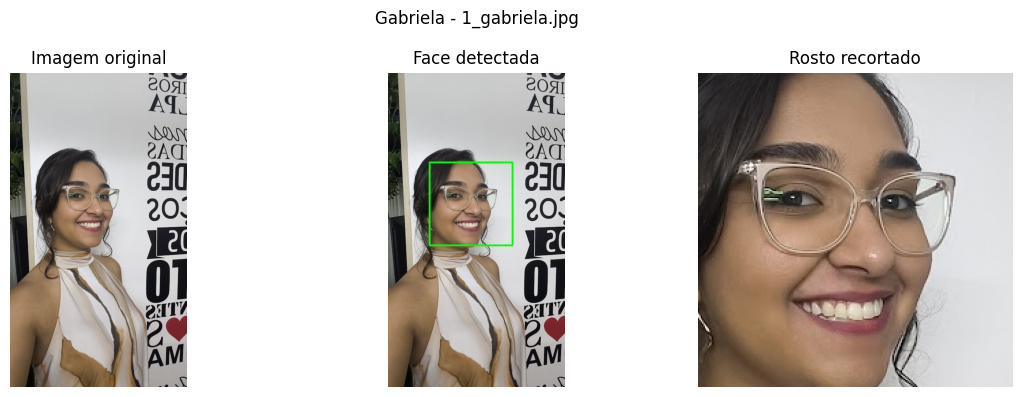

In [59]:
visualizar_deteccao(
    resultado,
    titulo=f"{pessoa_teste} - {imagem_teste.name}"
)

Executar para todas as imagens

In [60]:
resultados_deteccao = {}

for pessoa, dados in dataset.items():

    resultados_deteccao[pessoa] = {
        "treino": [],
        "teste": None
    }

    print(f"\nProcessando: {pessoa}")

    # Imagens de treinamento
    for caminho in dados["treino"]:

        try:
            resultado = detectar_rosto(caminho)

            resultados_deteccao[pessoa]["treino"].append({
                "arquivo": caminho,
                "resultado": resultado
            })

            print(f"  OK   | {caminho.name}")

        except Exception as erro:
            print(f"  ERRO | {caminho.name} | {erro}")

    # Imagem de teste
    try:
        caminho = dados["teste"]

        resultado = detectar_rosto(caminho)

        resultados_deteccao[pessoa]["teste"] = {
            "arquivo": caminho,
            "resultado": resultado
        }

        print(f"  OK   | {caminho.name} [TESTE]")

    except Exception as erro:
        print(f"  ERRO | {caminho.name} | {erro}")


Processando: Gabriela
  OK   | 1_gabriela.jpg
  OK   | 2_gabriela.jpg
  OK   | 3_gabriela.jpg
  OK   | 4_gabriela.jpg
  OK   | 5_gabriela.jpg [TESTE]

Processando: Tom Holland
  OK   | 1_tom.jpg
  OK   | 2_tom.jpg
  OK   | 3_tom.jpg
  OK   | 4_tom.jpg
  OK   | 5_tom.jpg [TESTE]

Processando: Zendaya
  OK   | 1_zendaya.jpg
  OK   | 2_zendaya.jpg
  OK   | 3_zendaya.jpg
  OK   | 4_zendaya.jpg
  OK   | 5_zendaya.jpg [TESTE]


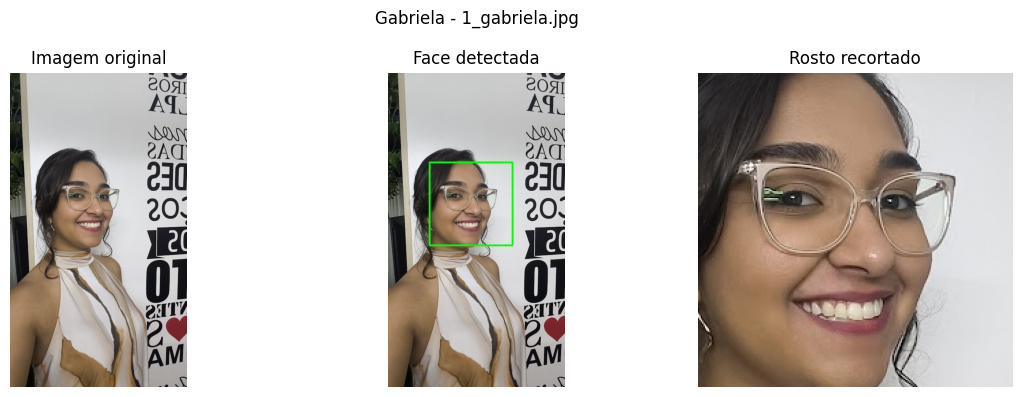

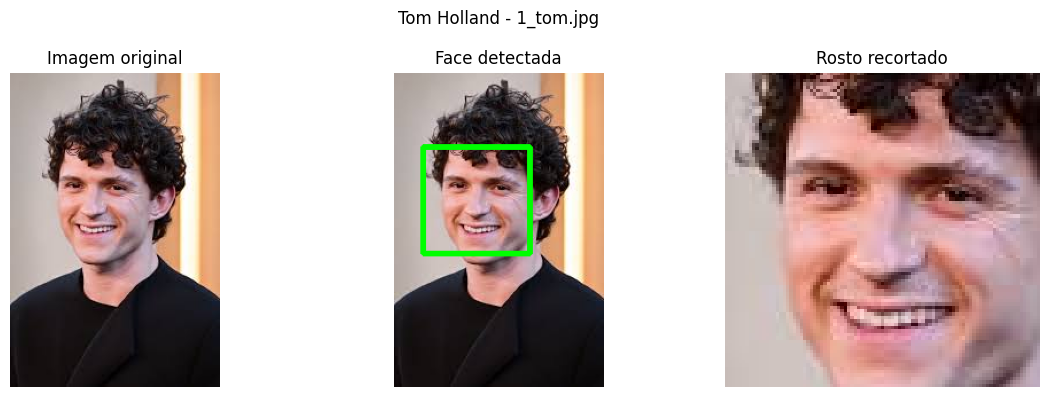

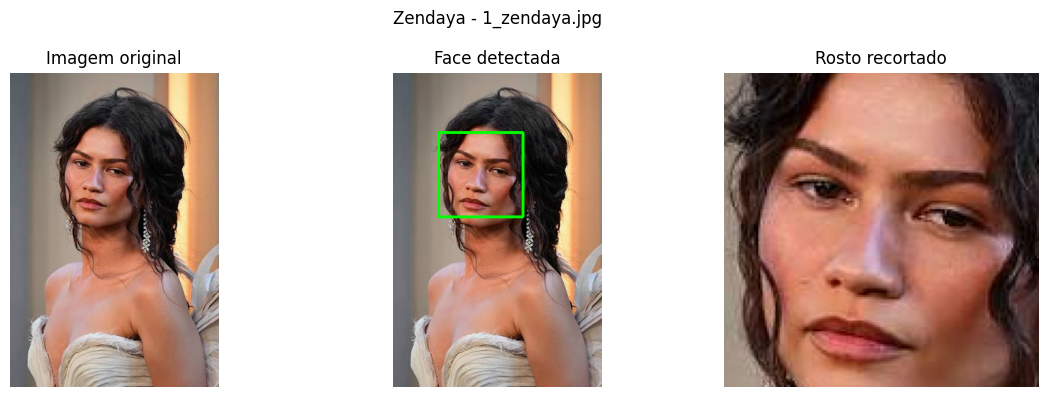

In [61]:
# Mostrando uma detecção de teste para cada pessoa
for pessoa, dados in resultados_deteccao.items():

    if dados["treino"]:

        exemplo = dados["treino"][0]

        visualizar_deteccao(
            exemplo["resultado"],
            titulo=f"{pessoa} - {exemplo['arquivo'].name}"
        )

# 4. Extração dos embeddings

In [ ]:
def extrair_embedding(caminho_imagem):

    resultado = DeepFace.represent(
        img_path=str(caminho_imagem),
        model_name=MODEL_NAME,
        detector_backend=DETECTOR_BACKEND,
        enforce_detection=True,
        align=True
    )

    if len(resultado) != 1:
        raise ValueError(
            f"Esperava exatamente 1 rosto em '{caminho_imagem.name}', "
            f"mas foram encontrados {len(resultado)}."
        )

    embedding = np.array(
        resultado[0]["embedding"],
        dtype=np.float32
    )

    return embedding

In [ ]:
pessoa_teste = list(dataset.keys())[0]
imagem = dataset[pessoa_teste]["treino"][0]

embedding = extrair_embedding(imagem)

print(f"Pessoa: {pessoa_teste}")
print(f"Imagem: {imagem.name}")
print(f"Dimensão do embedding: {embedding.shape}")
print(f"Primeiros valores: {embedding[:10]}")

Esses números passam a representar matematicamente as caracteristicas faciais extraidas pelo nosso código/modelo

In [ ]:
# Gerando embeddings para todas as imagens de treino
embeddings_treino = {}

for pessoa, dados in dataset.items():

    print(f"\nProcessando: {pessoa}")

    embeddings_pessoa = []

    for caminho in dados["treino"]:

        embedding = extrair_embedding(caminho)
        embeddings_pessoa.append(embedding)

        print(f"  OK | {caminho.name} " f"| dimensão: {embedding.shape}")

    embeddings_treino[pessoa] = embeddings_pessoa

Para cada pessoa temos 4 vetores (foto X embedding)
Agora, calculamos a média de cada posição dos quatro vetores. Usamos a média para ter um **valor referência menos dependente de particularidades** de uma foto só (iluminição, expressão, angulação, etc)

In [ ]:
perfis_faciais = {}

for pessoa, embeddings in embeddings_treino.items():

    matriz_embeddings = np.array(embeddings)
    embedding_medio = np.mean(matriz_embeddings, axis=0)
    perfis_faciais[pessoa] = embedding_medio

    print(f"{pessoa}: " f"{len(embeddings)} embeddings -> " f"perfil {embedding_medio.shape}")

Validação

In [ ]:
print("Perfis faciais cadastrados:\n")

for pessoa, perfil in perfis_faciais.items():

    print(
        f"{pessoa:<20} "
        f"| dimensões: {perfil.shape[0]} "
        f"| norma: {np.linalg.norm(perfil):.4f}"
    )

# 5. Reconhecimento facial

In [ ]:
def calcular_similaridade(embedding_1, embedding_2):

    embedding_1 = embedding_1.reshape(1, -1)
    embedding_2 = embedding_2.reshape(1, -1)

    similaridade = cosine_similarity(
        embedding_1,
        embedding_2
    )[0][0]

    return float(similaridade)

Quanto maior a similaridade, mais próximas estão as representações faciais.

In [ ]:
def reconhecer_rosto(caminho_imagem, perfis_faciais):

    # Extrai o embedding da imagem recebida
    embedding_teste = extrair_embedding(caminho_imagem)

    # Normaliza o embedding
    embedding_teste = extrair_embedding(embedding_teste)

    similaridades = {}

    # Compara com todas as pessoas cadastradas
    for pessoa, perfil in perfis_faciais.items():

        similaridade = calcular_similaridade(embedding_teste, perfil)

        similaridades[pessoa] = similaridade

    # Pessoa com maior similaridade
    pessoa_identificada = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[pessoa_identificada]

    return {
        "pessoa": pessoa_identificada,
        "similaridade": melhor_similaridade,
        "similaridades": similaridades
    }

Testando com uma imagem

In [ ]:
pessoa_real = "Gabriela"

imagem_teste = dataset[pessoa_real]["teste"]

resultado = reconhecer_rosto(
    imagem_teste,
    perfis_faciais
)

print(f"Imagem: {imagem_teste.name}")
print(f"Pessoa real: {pessoa_real}")
print(f"Pessoa identificada: {resultado['pessoa']}")
print(
    f"Similaridade: "
    f"{resultado['similaridade']:.4f}"
)

In [ ]:
ranking = sorted(
    resultado["similaridades"].items(),
    key=lambda item: item[1],
    reverse=True
)

for pessoa, similaridade in ranking:
    print(
        f"{pessoa:<20} "
        f"{similaridade:.4f}"
    )

Resultado final

In [ ]:
def exibir_resultado_reconhecimento(
    caminho_imagem,
    resultado
):

    imagem = cv2.imread(str(caminho_imagem))
    imagem = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(5, 5))

    plt.imshow(imagem)

    plt.title(
        f"Identificado: {resultado['pessoa']}\n"
        f"Similaridade: "
        f"{resultado['similaridade']:.2%}"
    )

    plt.axis("off")
    plt.show()

In [ ]:
exibir_resultado_reconhecimento(
    imagem_teste,
    resultado
)

## Testando automáticamente para todas as pessoas

In [ ]:
resultados_reconhecimento = []

for pessoa_real, dados in dataset.items():

    imagem_teste = dados["teste"]

    resultado = reconhecer_rosto(
        imagem_teste,
        perfis_faciais
    )

    acertou = (
        resultado["pessoa"] == pessoa_real
    )

    resultados_reconhecimento.append({
        "pessoa_real": pessoa_real,
        "pessoa_identificada": resultado["pessoa"],
        "similaridade": resultado["similaridade"],
        "acertou": acertou
    })

    status = "CORRETO" if acertou else "INCORRETO"

    print(
        f"{pessoa_real:<20} -> "
        f"{resultado['pessoa']:<20} "
        f"| {resultado['similaridade']:.4f} "
        f"| {status}"
    )

Acompanhando os resultados

In [ ]:
df_resultados = pd.DataFrame(resultados_reconhecimento)

df_resultados

In [ ]:
total = len(df_resultados)

acertos = df_resultados["acertou"].sum()

acuracia = acertos / total

print(f"Acertos: {acertos}/{total}")
print(f"Acurácia: {acuracia:.2%}")

# 6. Caso "Desconhecido"

Hoje nosso código responde apenas "Qual pessoa cadastrada é mais parecida?", mas precisamos responder "Existe alguma pessoa cadsatrada suficientemente parecida?"

In [ ]:
def reconhecer_rosto(
    caminho_imagem,
    perfis_faciais,
    limiar
):
    embedding_teste = extrair_embedding(
        caminho_imagem
    )

    embedding_teste = normalizar_embedding(
        embedding_teste
    )

    similaridades = {}

    for pessoa, perfil in perfis_faciais.items():

        similaridade = calcular_similaridade(
            embedding_teste,
            perfil
        )

        similaridades[pessoa] = similaridade

    pessoa_mais_proxima = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[
        pessoa_mais_proxima
    ]

    if melhor_similaridade >= limiar:
        pessoa_identificada = pessoa_mais_proxima
    else:
        pessoa_identificada = "Desconhecido"

    return {
        "pessoa": pessoa_identificada,
        "pessoa_mais_proxima": pessoa_mais_proxima,
        "similaridade": melhor_similaridade,
        "similaridades": similaridades
    }

In [ ]:
# Medindo os desconhecidos
resultados_desconhecidos = []

DESCONHECIDOS_DIR = DATASET_DIR / "desconhecidos"

for caminho in sorted(DESCONHECIDOS_DIR.glob("*")):

    if not caminho.is_file():
        continue

    embedding = extrair_embedding(caminho)
    embedding = normalizar_embedding(embedding)

    similaridades = {}

    for pessoa, perfil in perfis_faciais.items():

        similaridades[pessoa] = calcular_similaridade(
            embedding,
            perfil
        )

    pessoa_mais_proxima = max(
        similaridades,
        key=similaridades.get
    )

    melhor_similaridade = similaridades[
        pessoa_mais_proxima
    ]

    resultados_desconhecidos.append({
        "imagem": caminho.name,
        "pessoa_mais_proxima": pessoa_mais_proxima,
        "similaridade": melhor_similaridade
    })

In [ ]:
df_desconhecidos = pd.DataFrame(
    resultados_desconhecidos
)

df_desconhecidos

Calibrando o threshold

In [ ]:
limiares = np.arange(
    0.30,
    0.91,
    0.01
)

# 7. Avaliação do modelo